# Bitcoin: extending version 3 — Filip

**Task (unchanged).** From the last 7 days of hourly data, predict for each of the next 24 hours how much the price grows or shrinks compared with the hour before: `Close[h] / Close[h-1] − 1`, in %.

Alberto's `bitcoin-models-v3.ipynb` showed that the **size** of each of the 24 next hourly moves is predictable (long format, R² ≈ 0.12), that **80% ranges** can be given for every hour (coverage 76–78%), and that the **direction** is almost noise. This notebook builds on his setup (same data, the same train / validation / test blocks, the same long format) and tests four things he listed as open:

| # | Question | Section |
|---|---|---|
| 1 | Do the Binance order-flow and ETH attributes (from `binance-features.ipynb`) improve the forecast of the hourly move size? | 2 |
| 2 | Does **refitting every month**, with more weight on recent data, help? (his ideas 2 and 3) | 3 |
| 3 | Can the 80% ranges be made to really cover 80% (**conformal prediction**, his idea 1)? | 4 |
| 4 | Is the **hour +1 reversal** stable on his split, i.e. is there any usable direction signal? | 5 |

Every choice (hyperparameters, half-life, calibration window) is made on the validation block or only with data known at the forecast origin; the test block (Jul 2024 → Oct 2026) is used once.

## 1. Setup

Alberto's data, features, blocks and long format come from `bitcoin-models-v3.ipynb` through `shared_cells.py` (his cells are executed, not copied). The Binance attributes come from `binance_features.py`.

- `P[block]`, `Y[block]`, `D[block]`: positions in the hourly series, next 24 returns (%) and origins of every block (train and validation use every 6th origin, test every origin).
- `Xl(block, cols, hcols)`: long format, 24 rows per origin; `hcols` are the per-hour features (hours ahead, calendar of the predicted hour, and B3: hour profile, |r| of the same hour 1 and 7 days earlier, …).

In [1]:
from shared_cells import run_shared_cells

run_shared_cells(globals(), "v3")

from scipy.stats import binomtest
from binance_features import load_binance, build_attributes

btc, eth = load_binance("BTCUSDT"), load_binance("ETHUSDT")
groups = build_attributes(btc, eth)
G = {g: list(t.columns) for g, t in groups.items()}
FEAT = pd.concat([FEAT] + [t.reindex(hourly.index) for t in groups.values()], axis=1)   # Xl() reads FEAT
assert all(np.isfinite(FEAT[sum(G.values(), [])].values[P[k]]).all() for k in P), "missing Binance attributes"

# Leak check: Binance's change of the origin hour must equal ret_lag1 (computed from the Kaggle data)
c = U.safe_corr(btc["ret"].reindex(hourly.index[P["test"]]), FEAT["ret_lag1"].values[P["test"]])
print(f"Binance attributes: flow {len(G['flow'])}, eth {len(G['eth'])}, cross {len(G['cross'])} | "
      f"alignment check corr = {c:.4f}")
assert c > 0.99

HC = H_BASE + B3                                           # per-hour features used everywhere below
ya = {k: yl(k) for k in P}                                 # target: |hourly return|, long format

hourly series 2012-01-01 01:00:00 -> 2026-10-04 02:00:00 | features: base 42, B1 7, B2 6, B3 5 (per hour)
  train   7149 origins  2018-01-30 -> 2022-12-22
  val     2156 origins  2022-12-31 -> 2024-06-21
  test   19827 origins  2024-06-30 -> 2026-10-04


Binance attributes: flow 14, eth 12, cross 8 | alignment check corr = 0.9987


## 2. Binance attributes for the hourly move size

Same target and model family as Alberto's section 5 (|hourly return| in long format), with his base features + per-hour features as reference. Ridge and Gradient Boosting are tuned on the validation block, refitted on train + validation and evaluated once on test; *Ensemble* is their average.

In [2]:
COMBOS = {
    "Base (Alberto)":           BASE,
    "Base + order flow":        BASE + G["flow"],
    "Base + ETH":               BASE + G["eth"],
    "Base + ETH vs BTC":        BASE + G["cross"],
    "Base + all Binance":       BASE + G["flow"] + G["eth"] + G["cross"],
}
make_ridge = lambda alpha: make_pipeline(StandardScaler(), Ridge(alpha=alpha))
make_gb = lambda **p: HistGradientBoostingRegressor(early_stopping=False, max_iter=200, min_samples_leaf=1000,
                                                    random_state=RANDOM_STATE, **p)
rows = []
for name, cols in COMBOS.items():
    Xtr, Xva, Xte = Xl("train", cols, HC), Xl("val", cols, HC), Xl("test", cols, HC)
    Xtv, ytv = np.vstack([Xtr, Xva]), np.r_[ya["train"], ya["val"]]
    _, p_r = tune(make_ridge, {"alpha": [1, 100, 10_000]}, Xtr, ya["train"], Xva, ya["val"], vol_scores, name, show=False)
    t_g, p_g = tune(make_gb, {"learning_rate": [0.05, 0.1], "max_depth": [3, 6]}, Xtr, ya["train"], Xva, ya["val"],
                    vol_scores, name, show=False)
    pred_r = make_ridge(**p_r).fit(Xtv, ytv).predict(Xte)
    pred_g = make_gb(**p_g).fit(Xtv, ytv).predict(Xte)
    rows.append({"Combination": name, "attributes": len(cols), "GB params": p_g, "val R2 (GB)": t_g.loc[0, "score"],
                 "test R2 Ridge": U.r2(ya["test"], pred_r), "test R2 GB": U.r2(ya["test"], pred_g),
                 "test R2 Ensemble": U.r2(ya["test"], (pred_r + pred_g) / 2)})
binance_tab = pd.DataFrame(rows).set_index("Combination")
display(binance_tab.style.format({c: "{:.4f}" for c in binance_tab.columns if "R2" in c})
        .background_gradient(cmap="RdYlGn", subset=[c for c in binance_tab.columns if "test" in c], axis=None))

,attributes,GB params,val R2 (GB),test R2 Ridge,test R2 GB,test R2 Ensemble
Combination,,,,,,
Base (Alberto),42,"{'learning_rate': 0.1, 'max_depth': 3}",0.0913,0.1080,0.1230,0.1202
Base + order flow,56,"{'learning_rate': 0.1, 'max_depth': 3}",0.0923,0.1054,0.1205,0.1189
Base + ETH,54,"{'learning_rate': 0.1, 'max_depth': 3}",0.0933,0.1078,0.1236,0.1210
Base + ETH vs BTC,50,"{'learning_rate': 0.1, 'max_depth': 3}",0.0912,0.1074,0.1233,0.1206
Base + all Binance,76,"{'learning_rate': 0.05, 'max_depth': 6}",0.0906,0.1067,0.1258,0.1229


**What we see.** The Binance attributes do not change the result. Gradient Boosting on Alberto's base features reaches test R² **0.123**; with order flow, ETH or ETH vs BTC it stays between 0.121 and 0.126. On validation the differences are also ≤ 0.002, smaller than the effect of a different hyperparameter setting. Ridge gets slightly *worse* with more attributes. The size of the next hours' moves is already described by Bitcoin's own recent volatility and the clock; ETH and order flow repeat the same information.

## 3. Refitting every month, with more weight on recent data

Alberto's models are fitted once (mid-2024) and used for 2¼ years. In practice a model would be refitted regularly on everything known at that time. This matters here: the daily rhythm of volatility changed after 2024 (in `hourly-move-size.ipynb` the 14 UTC peak grew from 1.2× to 1.7× the average hour, probably because of the US spot ETFs).

**Simulation.** For every month of the evaluation period, Gradient Boosting (base + per-hour features, Alberto's best setting `learning_rate=0.1, max_depth=3`) is refitted on all origins whose 24 target hours ended **before the month starts** (every 6th origin since 2018), and predicts that month. Variants:

| Variant | Training rows |
|---|---|
| Fit once | train (+ validation, for the test block), Alberto's way |
| Monthly, expanding | everything before the month |
| Monthly, last 12 / 24 months | a rolling window |
| Monthly, half-life 6 / 12 / 24 months | everything, with weight `0.5 ** (age in months / half-life)` |

The variant is **chosen on the validation block** (the same simulation over Jan 2023 → Jun 2024) and then run once on test.

In [3]:
make_gb_best = lambda: HistGradientBoostingRegressor(early_stopping=False, max_iter=200, min_samples_leaf=1000,
                                                     learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE)
day_end = origins + pd.Timedelta(hours=24)
pool = np.flatnonzero(origins - pd.Timedelta(hours=U.MONTH - 1) >= DATA_START)[::STRIDE]
P["pool"], Y["pool"] = pos_all[pool], y_all[pool]
X_pool, y_pool = Xl("pool", BASE, HC), yl("pool")
pool_end, pool_origin = np.repeat(day_end[pool], 24), np.repeat(origins[pool], 24)

VARIANTS = {"Monthly, expanding": {}, "Monthly, last 12 months": {"window": 12}, "Monthly, last 24 months": {"window": 24},
            "Monthly, half-life 6 months": {"half_life": 6}, "Monthly, half-life 12 months": {"half_life": 12},
            "Monthly, half-life 24 months": {"half_life": 24}}

def refit_monthly(block, window=None, half_life=None):
    X_b, org = Xl(block, BASE, HC), np.repeat(D[block], 24)
    pred = np.empty(len(X_b))
    for m in pd.period_range(D[block][0], D[block][-1], freq="M"):
        start = m.start_time
        fit = pool_end < start                                           # targets known before the month
        if window:
            fit &= pool_origin >= start - pd.DateOffset(months=window)
        w = 0.5 ** ((start - pool_origin[fit]) / pd.Timedelta(days=30.44) / half_life) if half_life else None
        rows_m = (org >= start) & (org < (m + 1).start_time)
        pred[rows_m] = make_gb_best().fit(X_pool[fit], y_pool[fit], sample_weight=w).predict(X_b[rows_m])
    return pred

refit_pred, refit_rows = {}, []
for block, fit_end in [("val", VAL_START), ("test", TEST_START)]:
    once = pool_end < fit_end - WINDOW                                   # Alberto's split, with his 192 h purge
    refit_pred[block, "Fit once"] = make_gb_best().fit(X_pool[once], y_pool[once]).predict(Xl(block, BASE, HC))
    for v, kw in VARIANTS.items():
        refit_pred[block, v] = refit_monthly(block, **kw)
for v in ["Fit once"] + list(VARIANTS):
    refit_rows.append({"Variant": v, "val R2": U.r2(ya["val"], refit_pred["val", v]),
                       "test R2": U.r2(ya["test"], refit_pred["test", v]),
                       "test MAE": mean_absolute_error(ya["test"], refit_pred["test", v])})
refit_tab = pd.DataFrame(refit_rows).set_index("Variant")
CHOSEN = refit_tab.drop("Fit once")["val R2"].idxmax()
print(f"Chosen on the validation block: {CHOSEN}")
display(refit_tab.style.format("{:.4f}").background_gradient(cmap="RdYlGn", subset=["val R2", "test R2"]))

Chosen on the validation block: Monthly, half-life 12 months


,val R2,test R2,test MAE
Variant,,,
Fit once,0.0913,0.1241,0.2220
"Monthly, expanding",0.0959,0.1317,0.2214
"Monthly, last 12 months",0.0952,0.1331,0.2236
"Monthly, last 24 months",0.1035,0.1420,0.2214
"Monthly, half-life 6 months",0.1025,0.1440,0.2214
"Monthly, half-life 12 months",0.1045,0.1476,0.2203
"Monthly, half-life 24 months",0.1022,0.1449,0.2203


**Is the gain real?** Block bootstrap over test days (blocks of 10 consecutive days, Alberto's `U.block_bootstrap`) for the difference in R² between the chosen variant and "fit once", and R² per month.

R2 gain of 'Monthly, half-life 12 months' over 'fit once' on test: +0.0236 (95% CI +0.0179 to +0.0293)


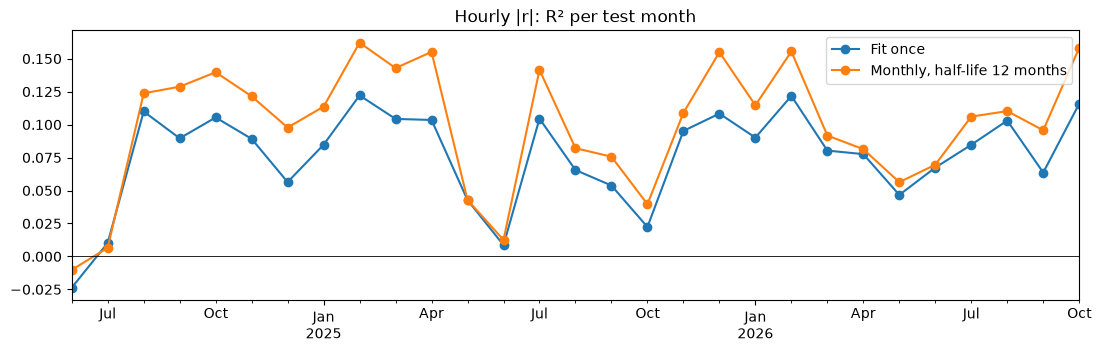

Monthly, half-life 12 months is better in 28 of 29 months


In [4]:
org_day = np.repeat(D["test"].normalize(), 24)
day_codes, days = pd.factorize(org_day)
y_te = ya["test"]
err_once = (y_te - refit_pred["test", "Fit once"]) ** 2
err_new = (y_te - refit_pred["test", CHOSEN]) ** 2
sst = (y_te - y_te.mean()) ** 2
per_day = lambda a: np.bincount(day_codes, a)
d_once, d_new, d_sst = per_day(err_once), per_day(err_new), per_day(sst)
diff = U.block_bootstrap(lambda i: (d_once[i].sum() - d_new[i].sum()) / d_sst[i].sum(), len(days), n_boot=1000, block=10)
print(f"R2 gain of '{CHOSEN}' over 'fit once' on test: {(d_once.sum() - d_new.sum()) / d_sst.sum():+.4f} "
      f"(95% CI {np.percentile(diff, 2.5):+.4f} to {np.percentile(diff, 97.5):+.4f})")

month = np.repeat(D["test"].to_period("M"), 24)
per_month = pd.DataFrame({v: pd.Series(y_te).groupby(month).apply(lambda s: U.r2(s.values, refit_pred["test", v][s.index]))
                          for v in ["Fit once", CHOSEN]})
ax = per_month.plot(marker="o", figsize=(13, 3.5), title="Hourly |r|: R² per test month")
ax.axhline(0, c="k", lw=0.6); ax.set_xlabel(""); plt.show()
print(f"{CHOSEN} is better in {(per_month[CHOSEN] > per_month['Fit once']).sum()} of {len(per_month)} months")

**What we see.**
- **Every monthly variant beats "fit once"**, on validation and on test, and recent data matters more than old data: a 24-month window beats the expanding one, and decaying weights beat a hard window (they keep the old data, but count it less).
- **Chosen on validation: half-life 12 months** (val R² 0.1045). On test it reaches **R² 0.148 vs 0.124** for the model fitted once (+19%), with lower MAE. The gain is clearly significant (95% CI +0.018 to +0.029) and holds in **28 of 29 test months**.
- For comparison: Alberto's whole set of 14 improvements took the test R² from 0.080 to 0.115–0.123. Keeping the model up to date adds about as much again, with the same model and features.

## 4. Calibrated 80% ranges (conformal prediction)

Alberto's quantile Gradient Boosting gives q10 and q90 for every hour; they covered 77% of the test hours instead of 80%. Conformal prediction corrects the width with errors measured on data the model was not fitted on. Here it is done in the scaled form: the interval is `centre ± f × half-width`, where `f` is the 80% quantile of `|y − centre| / half-width` on the calibration data (`f > 1` widens, `f < 1` narrows).

| Variant | Model fitted on | Calibration data for f |
|---|---|---|
| Raw | train + validation | none (f = 1) |
| Split conformal | train | the validation block (a fixed f) |
| Rolling conformal, 30 / 90 days | train + validation | the test hours of the last 30 / 90 days whose outcome is already known at the forecast origin (f updated every day) |
| Monthly refit + rolling conformal | refitted every month as in section 3 (chosen variant) | last 30 days |

Hyperparameters: `learning_rate=0.05, max_depth=3, min_samples_leaf=200, 200 trees` (close to Alberto's tuned settings; the interval width is not sensitive to them).

In [5]:
make_q = lambda tau: HistGradientBoostingRegressor(loss="quantile", quantile=tau, early_stopping=False, max_iter=200,
                                                   learning_rate=0.05, max_depth=3, min_samples_leaf=200,
                                                   random_state=RANDOM_STATE)
yr = {k: yl(k, "ret") for k in P}
XQ = {k: Xl(k, BASE, HC) for k in ("train", "val", "test")}
sigma_te = rule_abs("test")
tercile = pd.qcut(sigma_te, 3, labels=["calm", "middle", "wild"])

def fit_q(X, y, w=None):
    return [make_q(t).fit(X, y, sample_weight=w) for t in (0.1, 0.9)]

def centre_half(models, X):
    lo, hi = np.sort(np.column_stack([m.predict(X) for m in models]), axis=1).T
    return (lo + hi) / 2, (hi - lo) / 2

def f_quantile(y, centre, half):
    s = np.abs(y - centre) / half
    return np.quantile(s, min(1, np.ceil((len(s) + 1) * 0.8) / len(s)))

known_at = np.repeat(D["test"], 24) + pd.to_timedelta(np.tile(np.arange(1, 25), len(D["test"])), unit="h")
test_day = np.repeat(D["test"].normalize(), 24)

def rolling_f(centre, half, days_back):
    # f for each test day from the hours whose outcome was known at the start of that day
    score, f = np.abs(yr["test"] - centre) / half, np.ones(len(centre))
    order = np.argsort(known_at.values)
    k_sorted, s_sorted, org = known_at.values[order], score[order], np.repeat(D["test"], 24).values[order]
    for d in test_day.unique():
        lo_i, hi_i = np.searchsorted(k_sorted, [np.datetime64(d - pd.Timedelta(days=days_back)), np.datetime64(d)], side="right")
        if hi_i - lo_i >= 24 * 24 * 7:                       # at least a week of known outcomes; else f = 1
            f[test_day == d] = np.quantile(s_sorted[lo_i:hi_i], 0.8)
    return f

def interval_row(centre, half):
    lo, hi = centre - half, centre + half
    inside = (yr["test"] >= lo) & (yr["test"] <= hi)
    return {"coverage": inside.mean(), "width %": (hi - lo).mean(),
            **{f"coverage {c}": inside[tercile == c].mean() for c in ["calm", "middle", "wild"]},
            "pinball q10": U.pinball(yr["test"], lo, 0.1), "pinball q90": U.pinball(yr["test"], hi, 0.9)}

q_tv = fit_q(np.vstack([XQ["train"], XQ["val"]]), np.r_[yr["train"], yr["val"]])
c_tv, h_tv = centre_half(q_tv, XQ["test"])
q_tr = fit_q(XQ["train"], yr["train"])
c_tr, h_tr = centre_half(q_tr, XQ["test"])
f_split = f_quantile(yr["val"], *centre_half(q_tr, XQ["val"]))

intervals = {"Raw (Alberto)": (c_tv, h_tv), f"Split conformal (f = {f_split:.3f})": (c_tr, f_split * h_tr)}
for days_back in (30, 90):
    intervals[f"Rolling conformal, {days_back} days"] = (c_tv, rolling_f(c_tv, h_tv, days_back) * h_tv)

# monthly refit of the quantile models with the variant chosen in section 3, then rolling conformal
kw = VARIANTS[CHOSEN]
yr_pool, c_m, h_m = yl("pool", "ret"), np.empty(len(yr["test"])), np.empty(len(yr["test"]))
org_te = np.repeat(D["test"], 24)
for m in pd.period_range(D["test"][0], D["test"][-1], freq="M"):
    start = m.start_time
    fit = pool_end < start
    if kw.get("window"):
        fit &= pool_origin >= start - pd.DateOffset(months=kw["window"])
    w = 0.5 ** ((start - pool_origin[fit]) / pd.Timedelta(days=30.44) / kw["half_life"]) if kw.get("half_life") else None
    rows_m = (org_te >= start) & (org_te < (m + 1).start_time)
    c_m[rows_m], h_m[rows_m] = centre_half(fit_q(X_pool[fit], yr_pool[fit], w), XQ["test"][rows_m])
intervals["Monthly refit + rolling conformal, 30 days"] = (c_m, rolling_f(c_m, h_m, 30) * h_m)

fixed = np.quantile(np.r_[yr["train"], yr["val"]], [0.1, 0.9])
intervals["Baseline: fixed range"] = (np.full(len(c_tv), fixed.mean()), np.full(len(c_tv), (fixed[1] - fixed[0]) / 2))
conf_tab = pd.DataFrame({k: interval_row(*v) for k, v in intervals.items()}).T
display(conf_tab.style.format("{:.4f}").background_gradient(cmap="RdYlGn_r", subset=["pinball q10", "pinball q90"]))

,coverage,width %,coverage calm,coverage middle,coverage wild,pinball q10,pinball q90
Raw (Alberto),0.7687,0.8885,0.7603,0.7617,0.7840,0.0833,0.0810
Split conformal (f = 1.032),0.7698,0.8956,0.7527,0.7644,0.7923,0.0839,0.0820
"Rolling conformal, 30 days",0.7997,0.9779,0.7853,0.7931,0.8206,0.0833,0.0810
"Rolling conformal, 90 days",0.8017,0.9767,0.7912,0.7956,0.8182,0.0832,0.0809
"Monthly refit + rolling conformal, 30 days",0.8001,0.9814,0.7859,0.7975,0.8169,0.0823,0.0799
Baseline: fixed range,0.8758,1.2766,0.9446,0.8833,0.7996,0.0922,0.0912


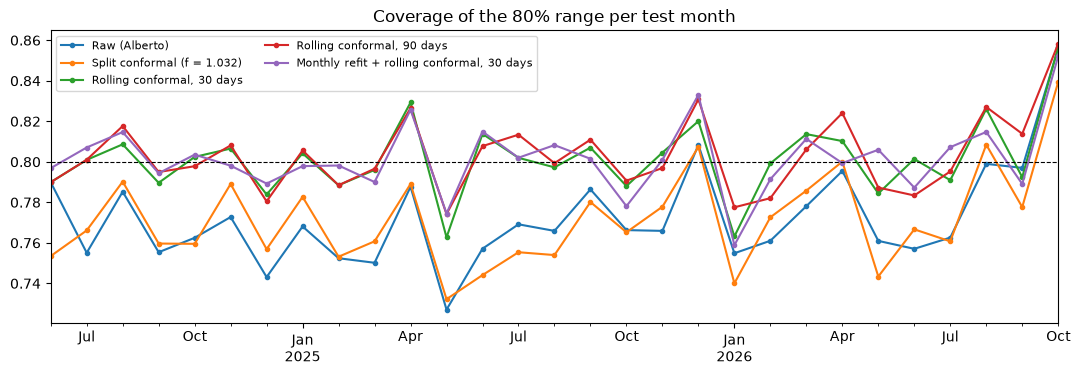

In [6]:
month = np.repeat(D["test"].to_period("M"), 24)
cov = pd.DataFrame({k: pd.Series((yr["test"] >= c - h) & (yr["test"] <= c + h)).groupby(month).mean()
                    for k, (c, h) in intervals.items() if not k.startswith("Baseline")})
ax = cov.plot(figsize=(13, 3.8), marker=".", title="Coverage of the 80% range per test month")
ax.axhline(0.8, c="k", ls="--", lw=0.8); ax.set_xlabel(""); ax.legend(fontsize=8, ncol=2); plt.show()

**What we see.**
- **Split conformal does not fix the coverage** (77.0%): on the validation block the raw intervals were almost right (f = 1.03), but the test period behaves differently again. A correction measured once goes out of date, like the model itself in section 3.
- **Rolling conformal reaches 80.0% (30 days) and 80.2% (90 days)** and keeps 79–82% in calm, middle and wild hours. The price is a 10% wider interval (0.98% instead of 0.89%), still **23% narrower than the fixed range**, which over-covers calm hours (94%) and under-covers wild ones (80%).
- **Monthly refit + rolling conformal** gives the same coverage (80.0%) with the lowest pinball loss of all (q10 0.0823, q90 0.0799): the refitted quantiles are sharper, the calibration keeps them honest.
- **Per month (plot):** the raw and split-conformal intervals stay below 80% in almost every month (73–80%), so the problem is systematic, not bad luck. The rolling versions move around 80% (76–83% per month).

## 5. Direction of the next hour on Alberto's split

In `binance-features.ipynb` (test Oct 2023 → Oct 2026) the next hour's direction had a small but significant signal (AUC ≈ 0.535), mostly the reversal of the last hour. Alberto (section 4 of v3) found the reversal at lag 1 but called it unstable. Here the same question on his blocks:

- **Reversal rule:** "the next hour goes the opposite way of the last hour", no learning.
- **Gradient Boosting classifier** for "next hour up?", on base features and on base + all Binance attributes, tuned on validation by AUC.

Metrics on every test hour (≈ 19,800): AUC, and the accuracy on the 10% most confident forecasts (binomial test against 50%).

In [7]:
y1 = {k: Y[k][:, 0] for k in P}

def direction_row(score, y):
    nz = y != 0
    score, y = score[nz], y[nz]
    centred = score - np.median(score)
    top = np.argsort(-np.abs(centred))[:len(score) // 10]
    hits = (centred[top] > 0) == (y[top] > 0)
    return {"AUC": roc_auc_score(y > 0, score), "accuracy top 10%": hits.mean(),
            "p-value": binomtest(int(hits.sum()), len(top), 0.5, alternative="greater").pvalue}

dir_rows = {"Reversal rule": direction_row(-FEAT["ret_lag1"].values[P["test"]], y1["test"])}
make_clf = lambda **p: HistGradientBoostingClassifier(early_stopping=False, max_iter=200, random_state=RANDOM_STATE, **p)
for name, cols in {"GB classifier, base": BASE, "GB classifier, base + Binance": COMBOS["Base + all Binance"]}.items():
    Xtr, Xva, Xte = Xw("train", cols), Xw("val", cols), Xw("test", cols)
    val_auc = {tuple(p.items()): roc_auc_score(y1["val"] > 0, make_clf(**p).fit(Xtr, y1["train"] > 0).predict_proba(Xva)[:, 1])
               for p in ParameterGrid({"learning_rate": [0.03, 0.1], "max_depth": [2, 3], "min_samples_leaf": [200, 1000]})}
    p = dict(max(val_auc, key=val_auc.get))
    clf = make_clf(**p).fit(np.vstack([Xtr, Xva]), np.r_[y1["train"], y1["val"]] > 0)
    dir_rows[f"{name} {p}"] = {"val AUC": max(val_auc.values()), **direction_row(clf.predict_proba(Xte)[:, 1], y1["test"])}
display(pd.DataFrame(dir_rows).T.style.format({"val AUC": "{:.4f}", "AUC": "{:.4f}", "accuracy top 10%": "{:.3f}", "p-value": "{:.1e}"}))

,AUC,accuracy top 10%,p-value,val AUC
Reversal rule,0.5280,0.546,2.6e-05,nan
"GB classifier, base {'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 200}",0.5374,0.544,4.5e-05,0.5445
"GB classifier, base + Binance {'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 200}",0.5369,0.555,5.9e-07,0.5558


**What we see.**
- **The reversal is stable.** On Alberto's test block (Jul 2024 → Oct 2026, a period none of my earlier choices saw) the simple rule still has AUC **0.528**, and its 10% most confident forecasts are right **54.6%** of the time (p = 3×10⁻⁵). It was 0.533 / 55.2% on the Oct 2023 → Oct 2026 test period of `binance-features.ipynb`.
- **Gradient Boosting adds a little:** AUC **0.537** on base features. With the Binance attributes the AUC is the same (0.537), but the most confident 10% are right **55.5%** of the time (p = 6×10⁻⁷).
- This is a real but small effect for **one hour ahead only**: about 55 correct out of 100 confident calls, before any trading costs.

## 6. Conclusions

Numbers from the run on 10 October 2026 (Alberto's blocks: train 2018 → 2022, validation Jan 2023 → Jun 2024, test Jul 2024 → Oct 2026).

| Question | Answer | Test result |
|---|---|---|
| 1. Do Binance order flow / ETH help predict the size of the hourly moves? | **No** | R² 0.121–0.126 vs 0.123 without them |
| 2. Does refitting every month with recency weights help? | **Yes, clearly** | R² **0.148** vs 0.124 (CI of the gain +0.018 to +0.029), better in 28/29 months |
| 3. Can the 80% ranges be calibrated? | **Yes, with rolling conformal** | coverage **80.0%** (77% before), 79–82% in every volatility regime, 23% narrower than a fixed range |
| 4. Is there a usable direction signal? | **Only for the next hour, small but stable** | AUC 0.537; 55% correct on the 10% most confident calls (p < 10⁻⁴) |

**For the 24-hour task:** the best forecast this project has for "how much will each of the next 24 hours grow or shrink" is
- the **size** of each hour from Gradient Boosting in long format, **refitted every month with a 12-month half-life** (R² ≈ 0.15),
- an **80% range** for each hour from the quantile models with **rolling conformal calibration** (honest 80% coverage),
- and a **direction** only for the next hour (reversal of the last hour, ≈ 55% on confident calls); for hours 2–24 the direction stays a coin flip.

The common lesson of sections 3 and 4: Bitcoin's behaviour drifts (e.g. the new 14 UTC volatility peak since the ETFs), so **keeping models and calibrations up to date matters more than extra data sources**.